# Statistics of RustSec Dataset

In [4]:
import json
import cvss
from pathlib import Path
from typing import List, Optional, Dict, Any, Union, Literal
from pydantic import BaseModel, Field, field_validator,RootModel
from dataclasses import dataclass
from dataclasses import field
from collections import namedtuple,Counter

class Package(BaseModel):
    name: str
    ecosystem: str
    purl: Optional[str] = None

class RangeEvent(BaseModel):
    introduced: Optional[str] = None
    fixed: Optional[str] = None

class Range(BaseModel):
    type: str
    events: List[RangeEvent]

class Affected(BaseModel):
    package: Package
    ranges: List[Range] = []
    database_specific: Optional[Dict[str, Any]] = None

class Reference(BaseModel):
    type: str
    url: str
    def __hash__(self):
        return hash(f"{self.type}: {self.url}")

class Severity(BaseModel):
    type: str
    score: str #CVSS score
    
    def __hash__(self):
        return hash(f"{self.type}: {self.score}")
    
    def get_severity_score(self) -> float:

        try:
            if self.type.lower() == "cvss_v4":
                cvss_obj = cvss.CVSS4(self.score)
                return float(cvss_obj.base_score)
            if self.type.lower() == "cvss_v3":
                cvss_obj = cvss.CVSS3(self.score)
                return float(cvss_obj.base_score)
            return float(-1.0)
        except ValueError:
            print(f"Invalid severity score: {self.score}")
            return -1.0

class DatabaseSpecific(BaseModel):
    cwe_ids: List[str] = Field(default_factory=list)
    severity: Optional[str] = None
    github_reviewed: Optional[bool] = None
    
    class Config:
        extra = "allow" 

class Advisory(BaseModel):
    schema_version: str
    id: str
    published: str
    modified: str
    aliases: List[str] = Field(default_factory=list)
    summary: str
    details: str
    affected: List[Affected] = []
    references: List[Reference] = []
    severity: List[Severity] = []
    database_specific: Optional[DatabaseSpecific] = None

    def get_severity_score(self) -> float:
        severity_score = 0.0
        if not self.severity:
            return -1.0
        if len(self.severity)>1:
            max_sev = -1.0
            for sev in self.severity:
                if sev.type == "CVSS_V4":
                    severity_score = sev.get_severity_score()
                    return severity_score
                max_sev = max(max_sev, sev.get_severity_score())
            return max_sev
        if len(self.severity)==1:
            return self.severity[0].get_severity_score()

    def merge_rustsec_data(self, rustsec_advisory: 'Advisory'):
        if self.summary.lower() != rustsec_advisory.summary.lower():
            if rustsec_advisory.summary:
                self.summary = f"{self.summary}\n{rustsec_advisory.summary}"
        if self.details.lower() != rustsec_advisory.details.lower():
            if rustsec_advisory.details:
                self.details = f"{self.details}\n{rustsec_advisory.details}"
        
        self.references = list(set(self.references).union(set(rustsec_advisory.references)))

        self.severity = list(set(self.severity).union(set(rustsec_advisory.severity)))

        current_cwes = set(self.database_specific.cwe_ids if self.database_specific else [])
        rustsec_cwes = set(rustsec_advisory.database_specific.cwe_ids if rustsec_advisory.database_specific else [])
        
        merged_cwes = list(current_cwes.union(rustsec_cwes))
        
        if self.database_specific:
            self.database_specific.cwe_ids = merged_cwes
        else:
            self.database_specific = DatabaseSpecific(cwe_ids=merged_cwes)


In [5]:
import copy
from collections import defaultdict

advisory_paths = Path("OSV").glob("*.json")
advisories:List[Advisory] = []
for p in advisory_paths:
    with open(p) as f:
        rustsec_data = json.load(f)
    rustsec_advisory = Advisory.model_validate(rustsec_data)
    advisories.append(rustsec_advisory)

print(f"{len(advisories)} advisories loaded.")

# --- Deduplication Logic (Per-Package & Restricted Filters) ---

# 1. Group by Package
advisories_by_package = defaultdict(list)
for adv in advisories:
    # If no affected packages, treat as isolated
    if adv.affected:
        for affected in adv.affected:
            pkg_name = affected.package.name
            # Deepcopy to ensure merging in one group doesn't affect another
            advisories_by_package[pkg_name].append(copy.deepcopy(adv))
    else:
        # Handle cases with no package info
        advisories_by_package["__unknown__"].append(copy.deepcopy(adv))

unique_advisories:List[Advisory] = []

# 2. Deduplicate within each package group
for pkg, pkg_advisories in advisories_by_package.items():
    grouped_unique: List[Advisory] = []
    
    for adv in pkg_advisories:
        is_duplicate = False
        
        # Filter references: only nvd or rustsec
        def get_filtered_refs(a):
            return set(ref.url for ref in a.references if "nvd" in ref.url or "rustsec" in ref.url)

        ref_urls_a = get_filtered_refs(adv)
        
        # Only attempt to find duplicates if we actually have valid references to match on
        if ref_urls_a:
            for u_adv in grouped_unique:
                ref_urls_b = get_filtered_refs(u_adv)
                
                # Intersection check
                if ref_urls_a & ref_urls_b:
                    is_duplicate = True
                    # print(f"Merging duplicate advisories for package '{pkg}': {adv.id} into {u_adv.id}")
                    u_adv.merge_rustsec_data(adv)
                    break
        
        if not is_duplicate:
            grouped_unique.append(adv)
            
    unique_advisories.extend(grouped_unique)

print(f"{len(unique_advisories)} unique advisories after deduplication (Per-Package strategy).")

# filter advisories without CWE category or severity score
filtered_advisories:List[Advisory] = []
for adv in unique_advisories:
    has_cwe = adv.database_specific and adv.database_specific.cwe_ids
    has_severity = adv.get_severity_score() >= 0.0
    if has_cwe and has_severity:
        filtered_advisories.append(adv)

print(f"{len(filtered_advisories)} advisories have CWE and severity score.")

1953 advisories loaded.
1467 unique advisories after deduplication (Per-Package strategy).
995 advisories have CWE and severity score.


In [6]:
class CWE(BaseModel):
    ID: int
    Name: str
    Description: str = ""
    Abstraction: Literal["Pillar", "Class", "Base", "Variant", "Compound"]
    Mapping: Literal["Allowed", "Allowed-with-Review", "Discouraged", "Prohibited"]
    Peer: List = Field(default_factory=list)
    Parent: List = Field(default_factory=list)
    Child: List[int] = Field(default_factory=list)

    def __str__(self) -> str:
        return f"CWE-{self.ID}: {self.Name}"

    def __hash__(self):
        return hash(str(self))

    def add_child(self, child_cwe: "CWE"):
        self.Child.append(child_cwe)
        child_cwe.Parent.append(self)


class CWEDatabase(RootModel):
    root: Dict[str, CWE]

    def get_by_id(self, id: int | str):
        name = f"CWE-{id}"
        return self.root[name]

    def get_by_name(self, name: str):
        return self.root[name]

class CWEHandler:
    def __init__(self, cwe_database: CWEDatabase):
        self.db = cwe_database
        self.setup_relationships()

    @classmethod
    def load_from_file(cls, file_path: str) -> "CWEHandler":
        import json

        with open(file_path, "r") as f:
            data = json.load(f)
        # CWEDatabase expects a dict where keys are CWE IDs (strings) and values are CWE objects
        db = CWEDatabase.model_validate(data)
        return cls(db)

    def setup_relationships(self):
        """
        Build the parent-child relationships (DAG) based on the 'Child' field (List[int]).
        Populates the 'Parent' field (List[CWE]) for each CWE.
        """
        # First pass: Convert any integer IDs in Parent to CWE objects or clear if invalid
        for cwe in self.db.root.values():
            cleaned_parents = []
            for p in cwe.Parent:
                if isinstance(p, CWE):
                    cleaned_parents.append(p)
                elif isinstance(p, int):
                    try:
                        parent_cwe = self.db.get_by_id(p)
                        cleaned_parents.append(parent_cwe)
                    except KeyError:
                        pass
            cwe.Parent = cleaned_parents

        # Second pass: Build relationships from Child fields
        for cwe_key, cwe in self.db.root.items():
            for child_id in cwe.Child:
                try:
                    child_cwe = self.db.get_by_id(child_id)
                    # Add current cwe as parent to the child
                    # Check if already exists to avoid duplicates if run multiple times
                    if cwe not in child_cwe.Parent:
                        child_cwe.Parent.append(cwe)
                except KeyError:
                    # Child ID might not exist in the database
                    continue

    def get_cwe(self, cwe_id: Union[int, str]) -> Optional[CWE]:
        try:
            if isinstance(cwe_id, int):
                return self.db.get_by_id(cwe_id)
            elif isinstance(cwe_id, str):
                if cwe_id.startswith("CWE-"):
                    return self.db.root[cwe_id]
                else:
                    return self.db.get_by_id(int(cwe_id))
        except (KeyError, ValueError):
            return None

    def get_direct_children(self, cwe_id: Union[int, str]) -> List[CWE]:
        cwe = self.get_cwe(cwe_id)
        if not cwe:
            return []
        children = []
        for child_id in cwe.Child:
            child = self.get_cwe(child_id)
            if child:
                children.append(child)
        return children

    def get_direct_parents(self, cwe_id: Union[int, str]) -> List[CWE]:
        cwe = self.get_cwe(cwe_id)
        if not cwe:
            return []
        return cwe.Parent

    def get_all_descendants(self, cwe_id: Union[int, str]) -> List[CWE]:
        cwe = self.get_cwe(cwe_id)
        if not cwe:
            return []
        descendants = set()
        queue = [cwe]
        while queue:
            current = queue.pop(0)
            for child_id in current.Child:
                child = self.get_cwe(child_id)
                if child and child not in descendants:
                    descendants.add(child)
                    queue.append(child)
        return list(descendants)

    def get_root_parents(self, cwe_id: Union[int, str]) -> List[CWE]:
        """
        Recursively find the most root parents (Pillars).
        """
        cwe = self.get_cwe(cwe_id)
        if not cwe:
            return []

        roots = set()
        queue = [cwe]
        visited = set()

        while queue:
            current = queue.pop(0)
            if current in visited:
                continue
            visited.add(current)

            # If it's a Pillar, it's a root
            if current.Abstraction == "Pillar":
                roots.add(current)
                continue  # Stop traversing up from a Pillar? Usually yes.

            # If no parents, it's a root
            if not current.Parent:
                roots.add(current)
                continue

            # Otherwise, traverse up
            for parent in current.Parent:
                queue.append(parent)

        return list(roots)

    def is_related(self, id1: Union[int, str], id2: Union[int, str]) -> bool:
        """
        Check if there is any inheritance relationship between two CWEs.
        Returns True if id1 is ancestor of id2 OR id2 is ancestor of id1.
        """
        cwe1 = self.get_cwe(id1)
        cwe2 = self.get_cwe(id2)

        if not cwe1 or not cwe2:
            return False

        if cwe1 == cwe2:
            return True

        # Check if cwe1 is ancestor of cwe2
        if self._is_ancestor(cwe1, cwe2):
            return True

        # Check if cwe2 is ancestor of cwe1
        if self._is_ancestor(cwe2, cwe1):
            return True

        return False

    def _is_ancestor(self, ancestor: CWE, descendant: CWE) -> bool:
        # BFS up from descendant to find ancestor
        queue = [descendant]
        visited = set()
        while queue:
            current = queue.pop(0)
            if current in visited:
                continue
            visited.add(current)

            if current == ancestor:
                return True

            for parent in current.Parent:
                queue.append(parent)
        return False


## CWE-Id statistics

In [7]:

cwe_handler = CWEHandler.load_from_file("../rq5/auditor/cwe_dict.json")

cwe_result = []
cwe_pillar_result = []
for f_adv in filtered_advisories:
    cwe_ids = f_adv.database_specific.cwe_ids if f_adv.database_specific else []
    cwe_result.extend(cwe_ids)

    for cwe_id in cwe_ids:
        root_parents = cwe_handler.get_root_parents(cwe_id)
        for parent in root_parents:
            if parent.Abstraction == "Pillar":
                cwe_pillar_result.append(f"CWE-{parent.ID}")


cwe_counter = Counter(cwe_result)
print(f"Total unique CWE IDs: {len(set(cwe_result))}")


print("Top 10 CWE IDs by occurrence:")
for cwe_id, count in cwe_counter.most_common(10):
    print(f"{cwe_id}: {count}")

print(f"Total unique Pillar CWE IDs: {len(set(cwe_pillar_result))}")
print("Top 10 Pillar CWE IDs by occurrence:")
# cwe_pillar_counter_evm = Counter(cwe_pillar_result_evm["cwe_ids"])
cwe_pillar_counter = Counter(cwe_pillar_result)
for cwe_id, count in cwe_pillar_counter.most_common(10):
    print(f"{cwe_id}: {count}")


# print(cwe_pillar_counter.most_common(10))
# print(cwe_pillar_counter_evm.most_common(10))

Total unique CWE IDs: 173
Top 10 CWE IDs by occurrence:
CWE-120: 129
CWE-787: 62
CWE-362: 56
CWE-416: 46
CWE-119: 41
CWE-400: 41
CWE-125: 40
CWE-908: 40
CWE-770: 35
CWE-415: 30
Total unique Pillar CWE IDs: 10
Top 10 Pillar CWE IDs by occurrence:
CWE-664: 691
CWE-691: 143
CWE-693: 106
CWE-707: 100
CWE-284: 66
CWE-703: 60
CWE-682: 42
CWE-710: 19
CWE-435: 8
CWE-697: 5


In [8]:
cwe_handler = CWEHandler.load_from_file("../rq5/auditor/cwe_dict.json")
cwe_database = cwe_handler.db

# Aggregate severity info for weighted average calculation later
cwe_raw_stats = {} # cwe_id -> {'sum_score': float, 'count_rated': int}
res = {"cwe_name": [], "severity_score": []}

for f_adv in filtered_advisories:
    cwe_ids = f_adv.database_specific.cwe_ids if f_adv.database_specific else []
    severity_score = f_adv.get_severity_score()
    for cwe_id in cwe_ids:
        id_int = int(cwe_id.replace("CWE-", ""))
        res["cwe_name"].append(id_int)
        res["severity_score"].append((id_int, severity_score))

for cwe_id, score in res["severity_score"]:
    if cwe_id not in cwe_raw_stats:
        cwe_raw_stats[cwe_id] = {'sum_score': 0.0, 'count_rated': 0}
    # print(f"CWE-{cwe_id} score: {score}")
    cwe_raw_stats[cwe_id]['sum_score'] += score
    cwe_raw_stats[cwe_id]['count_rated'] += 1

# Calculate average severity scores for each CWE (Individual)
cwe_count = Counter(res["cwe_name"])
cwe_severity = {}

for cwe_id, stats in cwe_raw_stats.items():
    if stats['count_rated'] > 0:
        cwe_severity[cwe_id] = stats['sum_score'] / stats['count_rated']
    else:
        cwe_severity[cwe_id] = 0

# Sort by frequency
cwe_count = dict(sorted(cwe_count.items(), key=lambda x: x[1], reverse=True))
cwe_count_backup = cwe_count.copy()
cwe_severity_backup = cwe_severity.copy()



# =============================================================================
# TOP SEVERITY ANALYSIS
# =============================================================================

print("\nTop 10 CWEs by Average Severity Score:")
original_severity_sorted = sorted(cwe_severity.items(), key=lambda x: x[1], reverse=True)

severity_rank = 0
for cwe_id, severity_score in original_severity_sorted:
    if severity_rank >= 10:
        break
    if cwe_count[cwe_id] > 5:  # Only show CWEs with significant occurrence
        try:
            cwe_info = cwe_database.get_by_id(cwe_id)
            print(f"CWE-{cwe_id}: {cwe_info.Name}, {cwe_count[cwe_id]}, {severity_score:.3f}")
            severity_rank += 1
        except Exception as e:
            pass



print("\nTop 10 Pillar CWEs by Average Severity Score (DAG-aware):")

pillars = [284, 435, 664, 682, 691, 693, 697, 703, 707, 710]
pillar_hierarchical_stats = []

for pillar_id in pillars:
    if not cwe_handler:
        continue
        
    descendants = cwe_handler.get_all_descendants(pillar_id)
    
    pillar_cwe = cwe_handler.get_cwe(pillar_id)
    relevant_cwes = [pillar_cwe] + descendants if pillar_cwe else descendants
    
    total_occurrence = 0
    total_weighted_severity_sum = 0
    total_rated_findings = 0
    cwes_with_severity = 0
    
    for cwe in relevant_cwes:
        cwe_id = cwe.ID
        count = cwe_count.get(cwe_id, 0)
        total_occurrence += count
        
        if cwe_id in cwe_raw_stats:
            stats = cwe_raw_stats[cwe_id]
            total_weighted_severity_sum += stats['sum_score']
            total_rated_findings += stats['count_rated']
            if stats['count_rated'] > 0:
                cwes_with_severity += 1
                
    # Calculate Pillar Average
    if total_rated_findings > 0:
        avg_severity = total_weighted_severity_sum / total_rated_findings
    else:
        avg_severity = 0
        
    pillar_hierarchical_stats.append((pillar_id, avg_severity, total_occurrence))

pillar_hierarchical_stats.sort(key=lambda x: x[1], reverse=True)

for pillar_id, avg_severity, total_count in pillar_hierarchical_stats:
    if avg_severity > 0:
        cwe_info = cwe_database.get_by_id(pillar_id)
        print(f"CWE-{pillar_id}: {cwe_info.Name}, {total_count} occurrences, {avg_severity:.3f} avg severity")




Top 10 CWEs by Average Severity Score:
CWE-704: Incorrect Type Conversion or Cast, 6, 9.033
CWE-415: Double Free, 30, 8.480
CWE-908: Use of Uninitialized Resource, 40, 8.480
CWE-122: Heap-based Buffer Overflow, 6, 8.317
CWE-787: Out-of-bounds Write, 62, 8.134
CWE-23: Relative Path Traversal, 9, 7.900
CWE-416: Use After Free, 46, 7.791
CWE-119: Improper Restriction of Operations within the Bounds of a Memory Buffer, 41, 7.771
CWE-1284: Improper Validation of Specified Quantity in Input, 6, 7.750
CWE-77: Improper Neutralization of Special Elements used in a Command ('Command Injection'), 24, 7.521

Top 10 Pillar CWEs by Average Severity Score (DAG-aware):
CWE-664: Improper Control of a Resource Through its Lifetime, 691 occurrences, 7.226 avg severity
CWE-707: Improper Neutralization, 100 occurrences, 7.192 avg severity
CWE-691: Insufficient Control Flow Management, 143 occurrences, 7.100 avg severity
CWE-693: Protection Mechanism Failure, 106 occurrences, 6.790 avg severity
CWE-703: Im

## Solana v.s Traditional Rust

/var/folders/t_/b4p6m_s51fj9ss8wlvrrmf9c0000gn/T/ipykernel_75626/2458344332.py:91: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{abs(tick):.1f}' for tick in ticks])


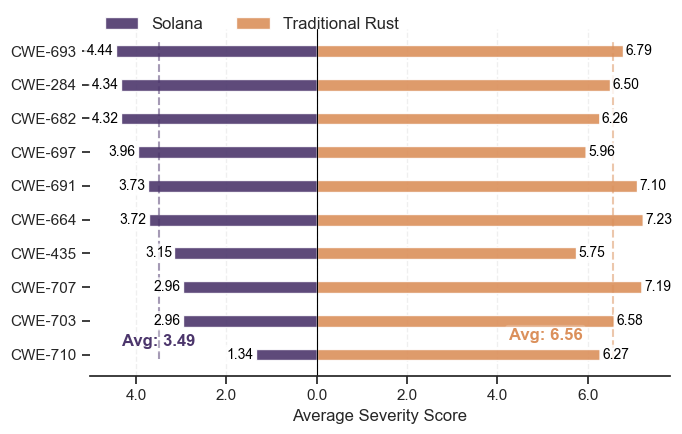

In [7]:
import pandas as pd

solana_data = [
    ('CWE-697', 34, 3.960),
    ('CWE-284', 161, 4.337),
    ('CWE-691', 149, 3.731),
    ('CWE-682', 260, 4.324),
    ('CWE-693', 157, 4.442),
    ('CWE-664', 270, 3.720),
    ('CWE-435', 52, 3.153),
    ('CWE-707', 248, 2.961),
    ('CWE-703', 118, 2.957),
    ('CWE-710', 301, 1.340)
]


rust_data = [
    ('CWE-693', 106, 6.790),
    ('CWE-664', 691, 7.226),
    ('CWE-284', 66, 6.502),
    ('CWE-707', 100, 7.192),
    ('CWE-691', 143, 7.100),
    ('CWE-682', 42, 6.260),
    ('CWE-703', 60, 6.582),
    ('CWE-435', 8, 5.750),
    ('CWE-697', 5, 5.960),
    ('CWE-710', 19, 6.268)
]
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


average_score_solana = sum([item[2] for item in solana_data]) / len(solana_data)
average_score_rust = sum([item[2] for item in rust_data]) / len(rust_data)

df_solana = pd.DataFrame(solana_data, columns=['CWE', 'Count', 'Avg_Severity'])
df_rust = pd.DataFrame(rust_data, columns=['CWE', 'Count', 'Avg_Severity'])

all_cwes = sorted(list(set(df_solana['CWE']) | set(df_rust['CWE'])))
df_combined = pd.DataFrame({'CWE': all_cwes})
df_combined = pd.merge(df_combined, df_solana[['CWE', 'Avg_Severity']], on='CWE', how='left').rename(columns={'Avg_Severity': 'Solana_Severity'})
df_combined = pd.merge(df_combined, df_rust[['CWE', 'Avg_Severity']], on='CWE', how='left').rename(columns={'Avg_Severity': 'EVM_Severity'})
df_combined = df_combined.fillna(0)
df_combined = df_combined.sort_values('Solana_Severity', ascending=True)

sns.set_theme(style="ticks")
colors = sns.color_palette("icefire")

solana_color = "#4c366c"
evm_color = "#db905b"

fig, ax = plt.subplots(figsize=(7, 4.5))

step=1
y = np.arange(len(df_combined))*step
bar_height = 0.35  # Thin bars

# Solana (Left side - negative values)
rects1 = ax.barh(y, -df_combined['Solana_Severity'], height=bar_height, label='Solana', color=solana_color, alpha=0.9)
# EVM (Right side - positive values)
rects2 = ax.barh(y, df_combined['EVM_Severity'], height=bar_height, label='Traditional Rust', color=evm_color, alpha=0.9)

# Average lines
ax.axvline(x=-average_score_solana, color=solana_color, linestyle='--', linewidth=1.5, alpha=0.5, ymin=0.05, ymax=0.97)
ax.axvline(x=average_score_rust, color=evm_color, linestyle='--', linewidth=1.5, alpha=0.5, ymin=0.05, ymax=0.97)

bbox_props_avg = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.2)
ax.text(-average_score_solana, 0.6, f'Avg: {average_score_solana:.2f}', color=solana_color, ha='center', va='top', fontsize=12, fontweight='bold', bbox=bbox_props_avg, zorder=20)
ax.text(average_score_rust-1.5, 0.78, f'Avg: {average_score_rust:.2f}', color=evm_color, ha='center', va='top', fontsize=12, fontweight='bold', bbox=bbox_props_avg, zorder=20)


bbox_props = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8)
for i, (idx, row) in enumerate(df_combined.iterrows()):
    # Solana label (left)
    if row['Solana_Severity'] > 0:
        ax.text(-row['Solana_Severity'] - 0.05, y[i], f"{row['Solana_Severity']:.2f}",va='center', ha='right', fontsize=10, color='black',bbox=bbox_props, zorder=10)
        
    # Rust label (right)
    if row['EVM_Severity'] > 0:
        ax.text(row['EVM_Severity'] + 0.05, y[i], f"{row['EVM_Severity']:.2f}", 
                va='center', ha='left', fontsize=10, color='black',bbox=bbox_props, zorder=10)

ax.set_yticks(y)
ax.set_yticklabels(df_combined['CWE'], ha='right')
ax.set_xlabel('Average Severity Score', fontsize=12)
# ax.set_title('Severity Comparison: Solana vs EVM', fontsize=14, pad=20)

ticks = ax.get_xticks()
ax.set_xticklabels([f'{abs(tick):.1f}' for tick in ticks])


ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False) # Remove left spine
# Add a center line
ax.axvline(0, color='black', linewidth=0.8)


ax.legend(loc='upper left', bbox_to_anchor=(0, 1.08), ncol=2, frameon=False, fontsize=12)

plt.tight_layout()
plt.show()
fig.savefig("rq4_severity.pdf", bbox_inches='tight',pad_inches=0)



## Exclude Informational Findings 

/var/folders/t_/b4p6m_s51fj9ss8wlvrrmf9c0000gn/T/ipykernel_75626/1129090731.py:91: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{abs(tick):.1f}' for tick in ticks])


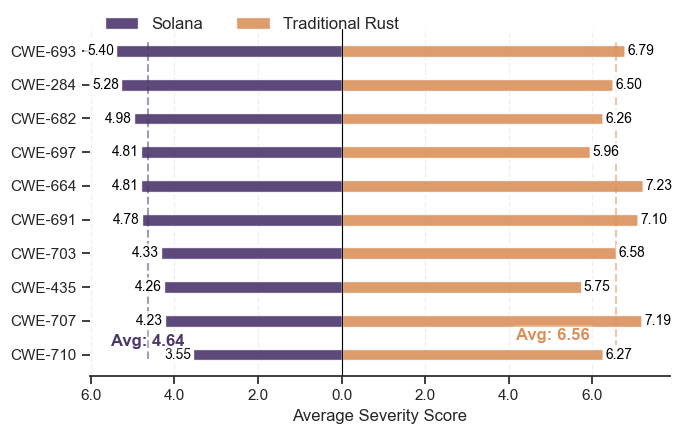

In [5]:
import pandas as pd


solana_data = [
    ('CWE-697', 28, 4.809),
    ('CWE-284', 130, 5.280),
    ('CWE-691', 118, 4.782),
    ('CWE-682', 221, 4.977),
    ('CWE-693', 125, 5.400),
    ('CWE-664', 207, 4.807),
    ('CWE-435', 39, 4.261),
    ('CWE-707', 173, 4.227),
    ('CWE-703', 81, 4.325),
    ('CWE-710', 116, 3.551)
]

rust_data = [
    ('CWE-693', 106, 6.790),
    ('CWE-664', 691, 7.226),
    ('CWE-284', 66, 6.502),
    ('CWE-707', 100, 7.192),
    ('CWE-691', 143, 7.100),
    ('CWE-682', 42, 6.260),
    ('CWE-703', 60, 6.582),
    ('CWE-435', 8, 5.750),
    ('CWE-697', 5, 5.960),
    ('CWE-710', 19, 6.268)
]
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


average_score_solana = sum([item[2] for item in solana_data]) / len(solana_data)
average_score_rust = sum([item[2] for item in rust_data]) / len(rust_data)

df_solana = pd.DataFrame(solana_data, columns=['CWE', 'Count', 'Avg_Severity'])
df_rust = pd.DataFrame(rust_data, columns=['CWE', 'Count', 'Avg_Severity'])

all_cwes = sorted(list(set(df_solana['CWE']) | set(df_rust['CWE'])))
df_combined = pd.DataFrame({'CWE': all_cwes})
df_combined = pd.merge(df_combined, df_solana[['CWE', 'Avg_Severity']], on='CWE', how='left').rename(columns={'Avg_Severity': 'Solana_Severity'})
df_combined = pd.merge(df_combined, df_rust[['CWE', 'Avg_Severity']], on='CWE', how='left').rename(columns={'Avg_Severity': 'EVM_Severity'})
df_combined = df_combined.fillna(0)
df_combined = df_combined.sort_values('Solana_Severity', ascending=True)

sns.set_theme(style="ticks")
colors = sns.color_palette("icefire")

solana_color = "#4c366c"
evm_color = "#db905b"

fig, ax = plt.subplots(figsize=(7, 4.5))

step=1
y = np.arange(len(df_combined))*step
bar_height = 0.35  # Thin bars

# Solana (Left side - negative values)
rects1 = ax.barh(y, -df_combined['Solana_Severity'], height=bar_height, label='Solana', color=solana_color, alpha=0.9)
# EVM (Right side - positive values)
rects2 = ax.barh(y, df_combined['EVM_Severity'], height=bar_height, label='Traditional Rust', color=evm_color, alpha=0.9)

# Average lines
ax.axvline(x=-average_score_solana, color=solana_color, linestyle='--', linewidth=1.5, alpha=0.5, ymin=0.05, ymax=0.97)
ax.axvline(x=average_score_rust, color=evm_color, linestyle='--', linewidth=1.5, alpha=0.5, ymin=0.05, ymax=0.97)

bbox_props_avg = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.2)
ax.text(-average_score_solana, 0.6, f'Avg: {average_score_solana:.2f}', color=solana_color, ha='center', va='top', fontsize=12, fontweight='bold', bbox=bbox_props_avg, zorder=20)
ax.text(average_score_rust-1.5, 0.78, f'Avg: {average_score_rust:.2f}', color=evm_color, ha='center', va='top', fontsize=12, fontweight='bold', bbox=bbox_props_avg, zorder=20)


bbox_props = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8)
for i, (idx, row) in enumerate(df_combined.iterrows()):
    # Solana label (left)
    if row['Solana_Severity'] > 0:
        ax.text(-row['Solana_Severity'] - 0.05, y[i], f"{row['Solana_Severity']:.2f}",va='center', ha='right', fontsize=10, color='black',bbox=bbox_props, zorder=10)
        
    # Rust label (right)
    if row['EVM_Severity'] > 0:
        ax.text(row['EVM_Severity'] + 0.05, y[i], f"{row['EVM_Severity']:.2f}", 
                va='center', ha='left', fontsize=10, color='black',bbox=bbox_props, zorder=10)

ax.set_yticks(y)
ax.set_yticklabels(df_combined['CWE'], ha='right')
ax.set_xlabel('Average Severity Score', fontsize=12)
# ax.set_title('Severity Comparison: Solana vs EVM', fontsize=14, pad=20)

ticks = ax.get_xticks()
ax.set_xticklabels([f'{abs(tick):.1f}' for tick in ticks])


ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False) # Remove left spine
# Add a center line
ax.axvline(0, color='black', linewidth=0.8)


ax.legend(loc='upper left', bbox_to_anchor=(0, 1.08), ncol=2, frameon=False, fontsize=12)

plt.tight_layout()
plt.show()
fig.savefig("rq4_severity.pdf", bbox_inches='tight',pad_inches=0)



       CWE  Count  Avg_Severity  Percentage
0  CWE-697     34         3.960    1.942857
1  CWE-284    161         4.337    9.200000
2  CWE-691    149         3.731    8.514286
3  CWE-682    260         4.324   14.857143
4  CWE-693    157         4.442    8.971429
5  CWE-664    270         3.720   15.428571
6  CWE-435     52         3.153    2.971429
7  CWE-707    248         2.961   14.171429
8  CWE-703    118         2.957    6.742857
9  CWE-710    301         1.340   17.200000
       CWE  Count  Avg_Severity  Percentage
0  CWE-693    106         6.790    8.548387
1  CWE-664    691         7.226   55.725806
2  CWE-284     66         6.502    5.322581
3  CWE-707    100         7.192    8.064516
4  CWE-691    143         7.100   11.532258
5  CWE-682     42         6.260    3.387097
6  CWE-703     60         6.582    4.838710
7  CWE-435      8         5.750    0.645161
8  CWE-697      5         5.960    0.403226
9  CWE-710     19         6.268    1.532258


/var/folders/t_/b4p6m_s51fj9ss8wlvrrmf9c0000gn/T/ipykernel_75626/3851646778.py:62: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{abs(tick):.0f}' for tick in ticks])


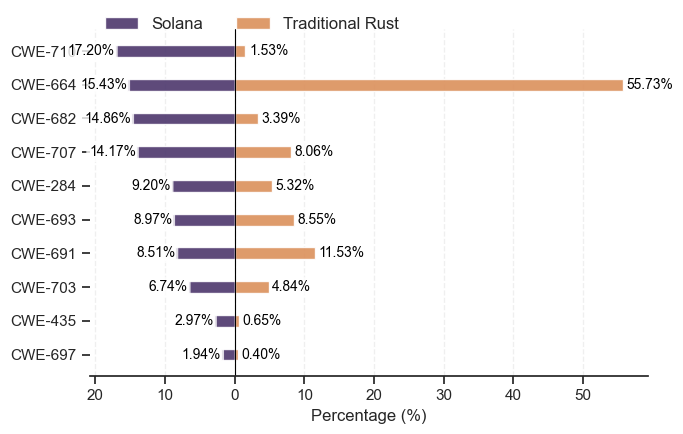

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

total_solana = sum(item[1] for item in solana_data)
total_rust = sum(item[1] for item in rust_data)

df_solana = pd.DataFrame(solana_data, columns=['CWE', 'Count', 'Avg_Severity'])
df_rust = pd.DataFrame(rust_data, columns=['CWE', 'Count', 'Avg_Severity'])

df_solana['Percentage'] = (df_solana['Count'] / total_solana) * 100
df_rust['Percentage'] = (df_rust['Count'] / total_rust) * 100
print(df_solana)
print(df_rust)

all_cwes = sorted(list(set(df_solana['CWE']) | set(df_rust['CWE'])))
df_combined = pd.DataFrame({'CWE': all_cwes})
df_combined = pd.merge(df_combined, df_solana[['CWE', 'Percentage']], on='CWE', how='left').rename(columns={'Percentage': 'Solana_Percentage'})
df_combined = pd.merge(df_combined, df_rust[['CWE', 'Percentage']], on='CWE', how='left').rename(columns={'Percentage': 'EVM_Percentage'})
df_combined = df_combined.fillna(0)

# Sort by Solana Percentage
df_combined = df_combined.sort_values('Solana_Percentage', ascending=True)


sns.set_theme(style="ticks")
colors = sns.color_palette("icefire")
solana_color = "#4c366c"
evm_color = "#db905b"

fig, ax = plt.subplots(figsize=(7, 4.5))

step = 1
y = np.arange(len(df_combined)) * step
bar_height = 0.35  # Thin bars

# Solana (Left side - negative values)
rects1 = ax.barh(y, -df_combined['Solana_Percentage'], height=bar_height, label='Solana', color=solana_color, alpha=0.9)
# EVM (Right side - positive values)
rects2 = ax.barh(y, df_combined['EVM_Percentage'], height=bar_height, label='Traditional Rust', color=evm_color, alpha=0.9)

# Average lines are not applicable for percentage distribution in the same way, removing them

bbox_props = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8)
# Add value annotations next to bars
for i, (idx, row) in enumerate(df_combined.iterrows()):
    # Solana label (left)
    if row['Solana_Percentage'] > 0:
        ax.text(-row['Solana_Percentage'] -0, y[i], f"{row['Solana_Percentage']:.2f}%", va='center', ha='right', fontsize=10, color='black', bbox=bbox_props)
        
    # EVM label (right)
    if row['EVM_Percentage'] > 0:
        ax.text(row['EVM_Percentage'] + 0.5, y[i], f"{row['EVM_Percentage']:.2f}%", va='center', ha='left', fontsize=10, color='black', bbox=bbox_props)

# Customizing axes
ax.set_yticks(y)
ax.set_yticklabels(df_combined['CWE'], ha='right')
ax.set_xlabel('Percentage (%)', fontsize=12)

ticks = ax.get_xticks()
ax.set_xticklabels([f'{abs(tick):.0f}' for tick in ticks])

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.axvline(0, color='black', linewidth=0.8)
ax.legend(loc='upper left', bbox_to_anchor=(0, 1.08), ncol=2, frameon=False, fontsize=12)


plt.tight_layout()
plt.show()

fig.savefig("rq4_frequency.pdf", bbox_inches='tight', pad_inches=0)

